# Notebook for ablation analysis
Note: Examplary ablation has only been performed for pruning percentile 95. If the entire results are needed, please run `ablation_percentiles.py` script for all percentiles.

In [ ]:
import os
import matplotlib.pyplot as plt
import matplotlib.cm as cm
import matplotlib.colors as mcolors
import pandas as pd

from rect_prune_ood.lib.util.paths import get_top_level_path

plt.rcParams.update({'text.usetex': False, 'font.family': 'serif'})	# LaTeX settings

In [ ]:
config = {
    'backbone': 'resnet50', 			# Backbone used for the ablation
    'severity': 1, 						# Severity of the imagenet-c perturbations
	'ablation_dataset': 'openimage-o',	# Dataset the ablation was run on
    'save_plots': True,				    # Whether to save the plots
}

all_percentiles = list(range(5, 105, 5))

ablation_result_dir = os.path.join(
	get_top_level_path(), 
    'results', 
    'ablation',
    config['ablation_dataset'],
    '1_percentiles'
)

plot_dir = os.path.join(get_top_level_path(), 'results', 'plots')	# Directory to save plots

imagenet_c_perturbations = [
	'brightness',
	'defocus_blur',
	'fog',
	'gaussian_blur',
	'glass_blur',
	'jpeg_compression',
	'pixelate',
	'shot_noise',
	'spatter',
	'zoom_blur',
	'contrast',
	'elastic_transform',
	'frost',
	'gaussian_noise',
	'impulse_noise',
	'motion_blur',
	'saturate',
	'snow',
	'speckle_noise',
]

num_perturbations = len(imagenet_c_perturbations)  
perturbation_indices = list(range(1, num_perturbations + 1))

In [9]:
percentile_results = {}
percentile_aurocs = {}
percentile_fprs = {}

for p in all_percentiles:

	percentile_file_path = os.path.join(
		ablation_result_dir, 
		f'{config['backbone']}_sev{config['severity']}_p{p}.csv'
	)

	if not os.path.isfile(percentile_file_path):
		print(f"File {percentile_file_path} for percentile {p} does not exist. Skipping...")
		continue

	df = pd.read_csv(percentile_file_path)

	df['AUROC'] = pd.to_numeric(df['AUROC'], errors='coerce')
	df['FPR'] = pd.to_numeric(df['FPR'], errors='coerce')

	df_sorted = df.sort_values(by=['AUROC', 'FPR'], ascending=[False, True])

	percentile_results[p] = df_sorted[['perturbation', 'AUROC', 'FPR']].to_dict(orient="records")

	percentile_aurocs[p] = df_sorted['AUROC'].tolist()
	percentile_fprs[p] = df_sorted['FPR'].tolist()

File /visinf/home/vilab17/RectPruneOOD/results/ablation/openimage-o/1_percentiles/resnet50_sev1_p5.csv for percentile 5 does not exist. Skipping...
File /visinf/home/vilab17/RectPruneOOD/results/ablation/openimage-o/1_percentiles/resnet50_sev1_p10.csv for percentile 10 does not exist. Skipping...
File /visinf/home/vilab17/RectPruneOOD/results/ablation/openimage-o/1_percentiles/resnet50_sev1_p15.csv for percentile 15 does not exist. Skipping...
File /visinf/home/vilab17/RectPruneOOD/results/ablation/openimage-o/1_percentiles/resnet50_sev1_p20.csv for percentile 20 does not exist. Skipping...
File /visinf/home/vilab17/RectPruneOOD/results/ablation/openimage-o/1_percentiles/resnet50_sev1_p25.csv for percentile 25 does not exist. Skipping...
File /visinf/home/vilab17/RectPruneOOD/results/ablation/openimage-o/1_percentiles/resnet50_sev1_p30.csv for percentile 30 does not exist. Skipping...
File /visinf/home/vilab17/RectPruneOOD/results/ablation/openimage-o/1_percentiles/resnet50_sev1_p35.cs

/tmp/ipykernel_608515/1001704758.py:7: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap = cm.get_cmap('cool')


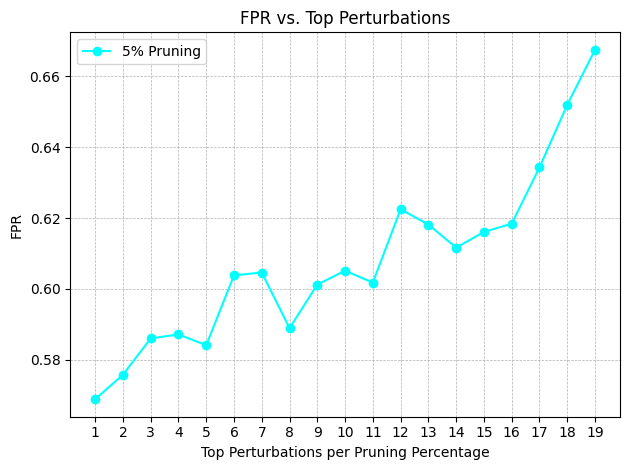

In [ ]:
metric = 'AUROC'	# 'AUROC' or 'FPR'

# Create color gradient from light blue to pink
cmap = cm.get_cmap('cool')
norm = mcolors.Normalize(vmin=min(all_percentiles), vmax=max(all_percentiles))
colors = ['black' if p == 100 else cmap(norm(100 - p)) for p in all_percentiles]

fig, ax = plt.subplots()
ax.set_xlabel('Top Perturbations per Pruning Percentage')
ax.set_ylabel(metric)
ax.set_xticks(perturbation_indices)
ax.grid(True, which='both', linestyle='--', linewidth=0.5)

for p, color in zip(all_percentiles, colors):

	if p in percentile_results:
		if metric == 'AUROC':
			metric_values = percentile_aurocs[p]
		elif metric == 'FPR':
			metric_values = percentile_fprs[p]

		label = f'{100 - p}% Pruning' if p == 5 or p == 95 or p == 100 else None

		if p == 100:
			label = 'baseline'

		marker = None if p == 100 else 'o'

		ax.plot(
			perturbation_indices,
			metric_values,
			marker=marker,
			linestyle='-',
			color=color,
			label=label,
		)

plt.title(f'{metric} vs. Top Perturbations')
plt.legend()
fig.tight_layout()

if config['save_plots']:
	metric_str = 'auroc' if metric == 'AUROC' else 'fpr'
	output_path = os.path.join(
		plot_dir, f'ablation_perturbations_{metric_str}_sorted.pdf'
	)  
	plt.savefig(output_path, format='pdf')

plt.show()